In [3]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

continuous_features =  ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
# survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
# survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

In [4]:
# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000464159],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls = ["Full"]

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Scale the training data using MinMaxScaler

scaler = MinMaxScaler()
x_train_scaled = data_x.copy()
cols_to_scale = [col for col in continuous_features if col in x_train_scaled.columns]
x_train_scaled[cols_to_scale] = scaler.fit_transform(x_train_scaled[cols_to_scale])

y_train = data_y

print("Training data scaled successfully")
print(f"Shape: {x_train_scaled.shape}")

Training data scaled successfully
Shape: (3227, 36)


In [6]:
import importlib
from functions import threshold as threshold_module

# Reload to ensure notebook uses the latest function signature/logic from functions/threshold.py
importlib.reload(threshold_module)

fit_dynamic_thresholds = threshold_module.fit_dynamic_thresholds
_build_risk_matrix = threshold_module._build_risk_matrix
assign_dynamic_risk_groups = threshold_module.assign_dynamic_risk_groups

# Compute thresholds dynamically for every day in the 5-year window (inclusive)
time_points = np.arange(1, 1826, dtype=float)
report_time_points = np.array([365, 730, 1000, 1095, 1460, 1825], dtype=float)

# Class-specific costs for high-threshold optimization
high_false_positive_cost = 1.0
high_true_negative_cost = 0.0
high_false_negative_cost = 50.0
high_true_positive_cost = 0.0

n_bootstrap = 50
low_percentile = 20  # percentile for low-risk cutoff from bootstrapped model outputs

# Base model used for threshold estimation
threshold_estimator = CoxnetSurvivalAnalysis(**best_params_for_calibration)

threshold_result = fit_dynamic_thresholds(
    estimator=threshold_estimator,
    x_train=x_train_scaled,
    y_train=y_train,
    time_points=time_points,
    n_bootstrap=n_bootstrap,
    low_percentile=low_percentile,
    low_threshold_method='bootstrap_percentile',
    intermediate_threshold_method="mean_risk",
    high_threshold_method='empirical_bayes',
    curve_spline_postprocess="all",
	curve_spline_variant="restricted",
	curve_spline_quantiles=(0.05, 0.275, 0.5, 0.725, 0.95), # (0.025, 0.1833, 0.3417, 0.5, 0.6583, 0.8167, 0.975)
    high_eb_shrink_k= 3.0, # tested several all gave the same results
    high_false_positive_cost=high_false_positive_cost,
    high_false_negative_cost=high_false_negative_cost,
    high_true_positive_cost=high_true_positive_cost,
    high_true_negative_cost=high_true_negative_cost,
    stratified_bootstrap=True,
    max_time_bins_for_bootstrap_strata=3,   
    prevalence_method='kaplan_meier', #'empirical_known',
    utility_weighting='ipcw', #'unweighted',
    threshold_estimation_method="point",
    random_state=12,
    verbose=True,
    log_every_bootstrap=10
)

thresholds_df = threshold_result.thresholds
thresholds_report = thresholds_df[thresholds_df['time'].isin(report_time_points)][
    ['time', 't_low', 't_intermediate', 't_high', 'event_prevalence', 'roc_n_used', 'roc_computable']
]
train_risk_scores = threshold_result.risk_scores_train
fitted_threshold_model = threshold_result.fitted_model

display(thresholds_report)
print('Full dynamic threshold table (daily) is stored in thresholds_df.')

[fit_dynamic_thresholds] Starting threshold fitting...
[fit_dynamic_thresholds] n_samples=3227, n_time_points=1825
[fit_dynamic_thresholds] bootstrap enabled with n_bootstrap=50
[fit_dynamic_thresholds] low_threshold_method=bootstrap_percentile
[fit_dynamic_thresholds] intermediate_threshold_method=mean_risk
[fit_dynamic_thresholds] high_threshold_method=empirical_bayes
[fit_dynamic_thresholds] low_percentile=20.00
[fit_dynamic_thresholds] Base model fitted in 0.19s
[fit_dynamic_thresholds] global_event_prevalence=0.0134, global_m_low=73.7367, global_m_high=1.4747
[fit_dynamic_thresholds] prevalence_method=kaplan_meier
[fit_dynamic_thresholds] utility_weighting=ipcw
[fit_dynamic_thresholds] threshold_estimation_method=point
[fit_dynamic_thresholds] Built train risk matrix in 0.99s
[fit_dynamic_thresholds] t=183 bootstrap 10/50
[fit_dynamic_thresholds] t=183 bootstrap 20/50
[fit_dynamic_thresholds] t=183 bootstrap 30/50
[fit_dynamic_thresholds] t=183 bootstrap 40/50
[fit_dynamic_thresho

,time,t_low,t_intermediate,t_high,event_prevalence,roc_n_used,roc_computable
364,365.0,0.000229,0.001157,0.008187,0.001586,3227,True
729,730.0,0.000655,0.003284,0.017626,0.003444,3227,True
999,1000.0,0.001145,0.005707,0.021018,0.005699,3227,True
1094,1095.0,0.001340,0.006663,0.022412,0.006185,3227,True
1459,1460.0,0.002084,0.010258,0.031230,0.009529,3227,True
1824,1825.0,0.002622,0.012840,0.038612,0.013380,3227,True


Full dynamic threshold table (daily) is stored in thresholds_df.


In [7]:
# Build dynamic risk scores for training data
train_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)

def assign_dynamic_4zone_groups(risk_matrix, threshold_df, time_points):
    """Assign 4 zones using 3 thresholds: t_low, t_intermediate, t_high."""
    time_points = list(time_points)
    labels = np.empty_like(risk_matrix, dtype=object)

    for j, t_value in enumerate(time_points):
        row = threshold_df.loc[threshold_df['time'] == float(t_value)]
        if row.empty:
            raise ValueError(f"Missing threshold row for time point {t_value}.")

        t_low = float(row.iloc[0]['t_low'])
        t_intermediate = float(row.iloc[0]['t_intermediate'])
        t_high = float(row.iloc[0]['t_high'])

        # Keep monotonic threshold order for robust zoning.
        t_low, t_intermediate, t_high = sorted([t_low, t_intermediate, t_high])
        col_scores = risk_matrix[:, j]

        labels[:, j] = np.where(
            col_scores < t_low,
            'zone_1_low',
            np.where(
                col_scores < t_intermediate,
                'zone_2_mid_low',
                np.where(col_scores < t_high, 'zone_3_mid_high', 'zone_4_high'),
            ),
        )

    columns = [f'risk_group_t_{int(t)}' for t in time_points]
    return pd.DataFrame(labels, columns=columns)

train_groups = assign_dynamic_4zone_groups(train_risk_matrix, thresholds_df, time_points)

# Extract event/time fields from Surv structured array
event_field = y_train.dtype.names[0]
time_field = y_train.dtype.names[1]
event_train = y_train[event_field].astype(bool)
time_train = y_train[time_field].astype(float)

def _safe_div(num, den):
    return float(num / den) if den > 0 else np.nan

def summarize_group_metrics_train(group_df, selected_times, event_vec, time_vec):
    rows = []
    risk_groups = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']

    for t in selected_times:
        # Known status at horizon t: event by t OR survived/censored at or after t
        known_mask = (time_vec >= float(t)) | (event_vec & (time_vec <= float(t)))
        if known_mask.sum() == 0:
            continue

        y_true = (event_vec[known_mask] & (time_vec[known_mask] <= float(t))).astype(int)
        col = f'risk_group_t_{int(t)}'
        labels_t = group_df.loc[known_mask, col].values

        total_events = int(np.sum(y_true == 1))
        total_nonevents = int(np.sum(y_true == 0))

        for grp in risk_groups:
            grp_mask = (labels_t == grp)
            n_group = int(np.sum(grp_mask))

            # Truth inside the group
            events_in_group = int(np.sum(y_true[grp_mask] == 1)) if n_group > 0 else 0
            nonevents_in_group = int(np.sum(y_true[grp_mask] == 0)) if n_group > 0 else 0

            # True confusion metrics from predictions (one-vs-rest for this group)
            y_pred = grp_mask.astype(int)
            tp = int(np.sum((y_pred == 1) & (y_true == 1)))
            fn = int(np.sum((y_pred == 0) & (y_true == 1)))
            fp = int(np.sum((y_pred == 1) & (y_true == 0)))
            tn = int(np.sum((y_pred == 0) & (y_true == 0)))

            sensitivity = _safe_div(tp, tp + fn)
            specificity = _safe_div(tn, tn + fp)

            rows.append({
                'dataset': 'train',
                'time': float(t),
                'risk_group': grp,
                'n_known_total': int(known_mask.sum()),
                'n_group': n_group,
                'events_in_group': events_in_group,
                'nonevents_in_group': nonevents_in_group,
                'event_rate_in_group': _safe_div(events_in_group, n_group),
                'group_share': _safe_div(n_group, int(known_mask.sum())),
                'event_capture': _safe_div(events_in_group, total_events),
                'nonevent_capture': _safe_div(nonevents_in_group, total_nonevents),
                'tp': tp,
                'fn': fn,
                'fp': fp,
                'tn': tn,
                'sensitivity_tpr': sensitivity,
                'specificity_tnr': specificity,
            })

    out = pd.DataFrame(rows)

    # Force all time x group combinations to be visible (including empty groups).
    zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
    full_index = pd.MultiIndex.from_product(
        [selected_times.astype(float), zone_order],
        names=['time', 'risk_group'],
    )
    out = (
        out.set_index(['time', 'risk_group'])
           .reindex(full_index)
           .reset_index()
    )
    out['dataset'] = out['dataset'].fillna('train')
    out['n_group'] = out['n_group'].fillna(0).astype(int)
    out['events_in_group'] = out['events_in_group'].fillna(0).astype(int)
    out['nonevents_in_group'] = out['nonevents_in_group'].fillna(0).astype(int)

    # Keep a stable, intuitive zone order in display.
    out['risk_group'] = pd.Categorical(
        out['risk_group'],
        categories=zone_order,
        ordered=True,
    )
    return out

group_metrics_train = summarize_group_metrics_train(
    train_groups,
    report_time_points,
    event_train,
    time_train,
)

# Long-format metrics
display(group_metrics_train.sort_values(['time', 'risk_group']))

# Wide-format patient counts per zone: always show all 4 zones
zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
zone_counts_train = (
    group_metrics_train
    .pivot(index='time', columns='risk_group', values='n_group')
    .reindex(columns=zone_order, fill_value=0)
    .rename_axis(columns=None)
    .reset_index()
)
print('Patients per zone (train, 4 zones):')
display(zone_counts_train)

,time,risk_group,dataset,n_known_total,n_group,events_in_group,nonevents_in_group,event_rate_in_group,group_share,event_capture,nonevent_capture,tp,fn,fp,tn,sensitivity_tpr,specificity_tnr
0,365.0,zone_1_low,train,3046,160,0,160,0.000000,0.052528,0.000000,0.052614,0,5,160,2881,0.000000,0.947386
1,365.0,zone_2_mid_low,train,3046,2010,0,2010,0.000000,0.659882,0.000000,0.660967,0,5,2010,1031,0.000000,0.339033
2,365.0,zone_3_mid_high,train,3046,791,1,790,0.001264,0.259685,0.200000,0.259783,1,4,790,2251,0.200000,0.740217
3,365.0,zone_4_high,train,3046,85,4,81,0.047059,0.027905,0.800000,0.026636,4,1,81,2960,0.800000,0.973364
4,730.0,zone_1_low,train,2376,422,0,422,0.000000,0.177609,0.000000,0.178360,0,10,422,1944,0.000000,0.821640
5,730.0,zone_2_mid_low,train,2376,1411,0,1411,0.000000,0.593855,0.000000,0.596365,0,10,1411,955,0.000000,0.403635
6,730.0,zone_3_mid_high,train,2376,470,1,469,0.002128,0.197811,0.100000,0.198225,1,9,469,1897,0.100000,0.801775
7,730.0,zone_4_high,train,2376,73,9,64,0.123288,0.030724,0.900000,0.027050,9,1,64,2302,0.900000,0.972950
8,1000.0,zone_1_low,train,2119,424,0,424,0.000000,0.200094,0.000000,0.201521,0,15,424,1680,0.000000,0.798479
9,1000.0,zone_2_mid_low,train,2119,1241,0,1241,0.000000,0.585654,0.000000,0.589829,0,15,1241,863,0.000000,0.410171


Patients per zone (train, 4 zones):


,time,zone_1_low,zone_2_mid_low,zone_3_mid_high,zone_4_high
0,365.0,160,2010,791,85
1,730.0,422,1411,470,73
2,1000.0,424,1241,326,128
3,1095.0,603,1021,291,128
4,1460.0,420,743,208,102
5,1825.0,199,679,195,108


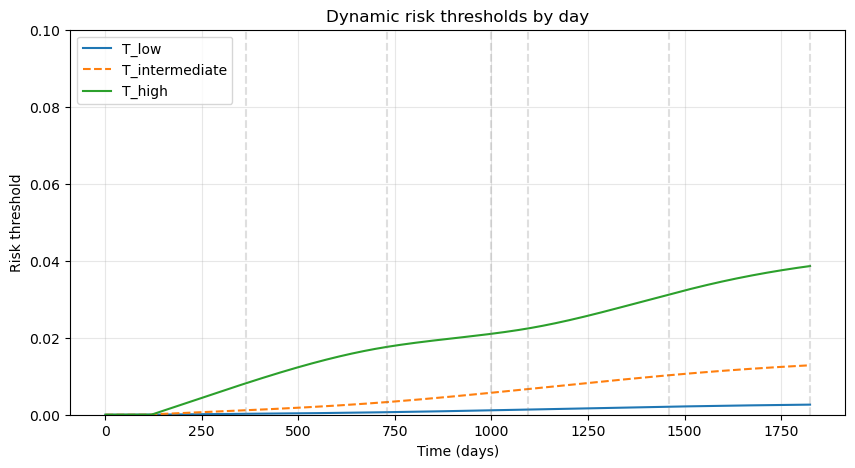

In [8]:
# Visual check: threshold evolution over time (daily)
plt.figure(figsize=(10, 5))
plt.plot(thresholds_df['time'], thresholds_df['t_low'], label='T_low')
plt.plot(
    thresholds_df['time'],
    thresholds_df['t_intermediate'],
    label=f"T_intermediate",
    linestyle='--',
)
plt.plot(thresholds_df['time'], thresholds_df['t_high'], label='T_high')

# Highlight key horizons
for t in report_time_points:
    plt.axvline(t, color='gray', linestyle='--', alpha=0.25)

plt.xlabel('Time (days)')
plt.ylabel('Risk threshold')
plt.ylim(0.0, 0.1)
plt.title('Dynamic risk thresholds by day')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

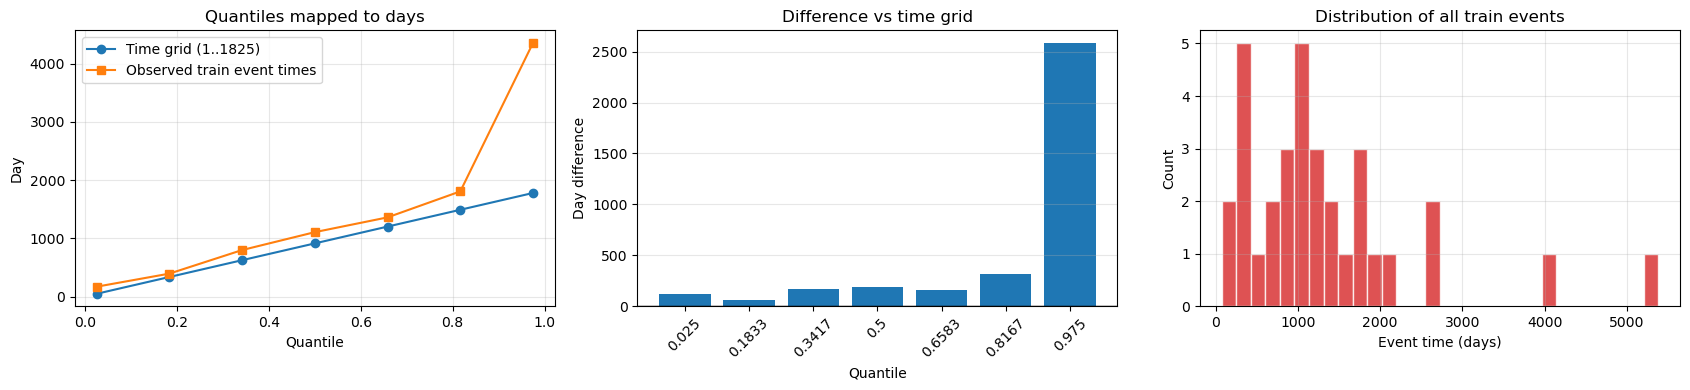

Quantile-day tables:


,quantile,day_on_time_grid,day_on_event_times_train
0,0.0250,46.6000,168.6000
1,0.1833,335.3392,393.1184
2,0.3417,624.2608,798.4096
3,0.5000,913.0000,1106.0000
4,0.6583,1201.7392,1360.0528
5,0.8167,1490.6608,1806.5264
6,0.9750,1779.4000,4358.6000


Total number of observed events in train set: 33


In [9]:
# Quantiles used in fit_dynamic_thresholds
q = np.array([0.025, 0.1833, 0.3417, 0.5, 0.6583, 0.8167, 0.975], dtype=float)

# Day correspondence on the model time grid (1..1825)
quantile_days = pd.DataFrame({
    "quantile": q,
    "day_on_time_grid": np.quantile(time_points, q)
})

# Event-only quantiles from train outcomes
event_times_train = y_train["time"][y_train["event"]]
quantile_days_event_only = pd.DataFrame({
    "quantile": q,
    "day_on_event_times_train": np.quantile(event_times_train, q)
})

# Merge for side-by-side plotting
quantile_compare = quantile_days.merge(quantile_days_event_only, on="quantile")

# Graphical view
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# Left: quantile -> day mapping
ax[0].plot(
    quantile_compare["quantile"],
    quantile_compare["day_on_time_grid"],
    marker="o",
    label="Time grid (1..1825)"
)
ax[0].plot(
    quantile_compare["quantile"],
    quantile_compare["day_on_event_times_train"],
    marker="s",
    label="Observed train event times"
)
ax[0].set_title("Quantiles mapped to days")
ax[0].set_xlabel("Quantile")
ax[0].set_ylabel("Day")
ax[0].grid(alpha=0.3)
ax[0].legend()

# Middle: difference (event-only - grid)
diff = quantile_compare["day_on_event_times_train"] - quantile_compare["day_on_time_grid"]
ax[1].bar(quantile_compare["quantile"].astype(str), diff)
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_title("Difference vs time grid")
ax[1].set_xlabel("Quantile")
ax[1].set_ylabel("Day difference")
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(axis="y", alpha=0.3)

# Right: all event times in train set
ax[2].hist(event_times_train, bins=30, alpha=0.8, color="tab:red", edgecolor="white")
ax[2].set_title("Distribution of all train events")
ax[2].set_xlabel("Event time (days)")
ax[2].set_ylabel("Count")
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Quantile-day tables:")
display(quantile_compare)

print(f"Total number of observed events in train set: {event_times_train.shape[0]}")

In [10]:
# Test-set evaluation using training-derived dynamic thresholds
from sksurv.metrics import concordance_index_censored
train_risk_score_global = fitted_threshold_model.predict(x_train_scaled)
c_index_train = concordance_index_censored(event_train, time_train, train_risk_score_global)[0]
print(f"Train Harrell C-index: {c_index_train:.4f}")

Train Harrell C-index: 0.9157


In [ ]:
import pickle
from pathlib import Path

# Fit Coxnet model
cox_model = CoxnetSurvivalAnalysis(**best_params_for_calibration)
cox_model.fit(x_train_scaled, y_train)

# Build coefficient table
coef_array = cox_model.coef_
if coef_array.ndim == 1:
    coef_values = coef_array
else:
    # best_params_for_calibration has one alpha, so take first column
    coef_values = coef_array[:, 0]

coef_df = pd.DataFrame({
    "feature": x_train_scaled.columns,
    "coefficient": coef_values
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Optional: non-zero coefficients only
nonzero_coef_df = coef_df[coef_df["coefficient"] != 0].reset_index(drop=True)
size = len(nonzero_coef_df)

print("All coefficients (sorted by absolute value):")
print(coef_df.to_string(index=False))

print(f"\nNon-zero coefficients ({size}):")
print(nonzero_coef_df.to_string(index=False))

# Save model-related variables to pickle
variables_to_save = [
    "best_params_for_calibration",
    "cox_model",
    "scaler",
    "x_train_scaled",
    "x_test_scaled",
    "y_train",
    "y_test",
    "coef_df",
    "nonzero_coef_df",
    "time_points",
    "report_time_points",
    "thresholds_df",
    "thresholds_report",
    "threshold_result",
    "fitted_threshold_model",
    "intermediate_threshold_method",
]

model_bundle = {name: globals()[name] for name in variables_to_save if name in globals()}
model_bundle["threshold_config"] = {
    "intermediate_threshold_method": globals().get("intermediate_threshold_method", None),
    "zone_scheme": "4-zones from t_low, t_intermediate, t_high",
    "threshold_columns_expected": ["time", "t_low", "t_intermediate", "t_high"],
}

# Save a reproducible train subsample as SurvSHAP reference background data
ref_size = min(200, len(x_train_scaled))
ref_idx = np.random.default_rng(42).choice(len(x_train_scaled), size=ref_size, replace=False)
X_ref = x_train_scaled.iloc[ref_idx].copy()
y_ref = y_train[ref_idx].copy()
model_bundle["X_ref"] = X_ref
model_bundle["y_ref"] = y_ref

pickle_path = "coxnet_model_bundle.pkl"
with open(pickle_path, "wb") as f:
    pickle.dump(model_bundle, f)

All coefficients (sorted by absolute value):
                                                  feature  coefficient  abs_coefficient
                  Adjuvant therapy using biological drugs    -2.112716         2.112716
                              Endocrine therapy performed     1.395059         1.395059
                      Oestrogen receptor status at CB_0.0     1.302172         1.302172
                      Oestrogen receptor status at CB_1.0    -0.783302         0.783302
Her2 overexpression (with immunohystochemistry) at CB_2.0    -0.695015         0.695015
               Treatment in association with chemotherapy     0.690035         0.690035
                                        Isotype at CB_4.0     0.684409         0.684409
                                          Grade at CB_3.0     0.590667         0.590667
                              Radiotherapy (RT) performed    -0.533433         0.533433
                                  Total administered dose    -0.489617     

In [5]:
import pickle
from pathlib import Path
from functions.threshold import *
pickle_path = "coxnet_model_bundle.pkl"

# Verify we can retrieve the new intermediate threshold from pickle
with open(pickle_path, "rb") as f:
    loaded_bundle = pickle.load(f)

loaded_thresholds = loaded_bundle.get("thresholds_df", pd.DataFrame())
has_new_threshold = (
    isinstance(loaded_thresholds, pd.DataFrame)
    and "t_intermediate" in loaded_thresholds.columns
)

print(f"Retrieved t_intermediate from pickle: {has_new_threshold}")
if not has_new_threshold:
    raise ValueError("Saved pickle does not contain t_intermediate in thresholds_df.")

Retrieved t_intermediate from pickle: True


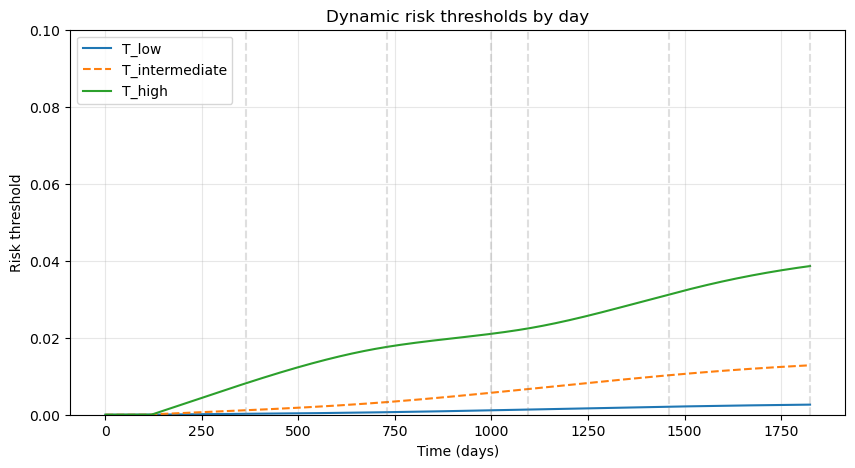

In [7]:
# Visual check: threshold evolution over time (daily) from the saved bundle
if "loaded_bundle" not in globals():
    raise NameError("loaded_bundle not found. Run the bundle-load cell first.")

bundle_thresholds_df = loaded_bundle.get("thresholds_df")
if not isinstance(bundle_thresholds_df, pd.DataFrame):
    raise TypeError("The loaded bundle does not contain a thresholds_df DataFrame.")

report_time_points_local = globals().get("report_time_points", np.array([365, 730, 1000, 1095, 1460, 1825], dtype=float))

plt.figure(figsize=(10, 5))
plt.plot(bundle_thresholds_df['time'], bundle_thresholds_df['t_low'], label='T_low')
plt.plot(
    bundle_thresholds_df['time'],
    bundle_thresholds_df['t_intermediate'],
    label="T_intermediate",
    linestyle='--',
)
plt.plot(bundle_thresholds_df['time'], bundle_thresholds_df['t_high'], label='T_high')

# Highlight key horizons
for t in report_time_points_local:
    plt.axvline(t, color='gray', linestyle='--', alpha=0.25)

plt.xlabel('Time (days)')
plt.ylabel('Risk threshold')
plt.ylim(0.0, 0.1)
plt.title('Dynamic risk thresholds by day')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [4]:
# Load model bundle so chart cells can run without refitting
import pickle
from pathlib import Path

# Preferred bundle first, with fallback for older naming
candidate_paths = [
    Path("coxnet_model_bundle.pkl")
]

bundle_path = next((p for p in candidate_paths if p.exists()), None)
if bundle_path is None:
    raise FileNotFoundError(
        "No model bundle found. Expected one of: "
        f"{[str(p) for p in candidate_paths]}"
    )

with open(bundle_path, "rb") as f:
    loaded_bundle = pickle.load(f)

if not isinstance(loaded_bundle, dict):
    raise TypeError(f"Bundle must be a dict, got {type(loaded_bundle)}")

# Restore all saved variables into notebook scope
for name, value in loaded_bundle.items():
    globals()[name] = value

# Common compatibility aliases used by downstream cells
if "fitted_threshold_model" not in globals() and "cox_model" in globals():
    fitted_threshold_model = cox_model
if "cox_model" not in globals() and "fitted_threshold_model" in globals():
    cox_model = fitted_threshold_model

if "thresholds_df" not in globals() and "threshold_result" in globals() and hasattr(threshold_result, "thresholds"):
    thresholds_df = threshold_result.thresholds

if "coef_df" not in globals() and "nonzero_coef_df" in globals() and isinstance(nonzero_coef_df, pd.DataFrame):
    coef_df = nonzero_coef_df.copy()

print(f"Loaded bundle: {bundle_path.resolve()}")
print(f"Keys loaded: {len(loaded_bundle)}")
print(f"coef_df available: {'coef_df' in globals()}")

Loaded bundle: C:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis_2\new_approaches\models\5y\coxnet_model_bundle.pkl
Keys loaded: 16
coef_df available: True


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Check if data exists
if 'coef_df' not in globals():
    raise NameError("coef_df not found. Run the bundle-load cell or coefficient-building cell first.")

# -------------------------
# Settings you can change
# -------------------------
use_nonzero_only = True
max_features_per_plot = 20  # Good limit for a PowerPoint slide
figsize = (10, 8)

# Dictionary to rename features in the chart. 
# Format: 'Original Name': 'New Custom Name'
feature_name_mapping = {
    'Oestrogen receptor status at CB_0.0': 'ER Status (Negative)',
    'Oestrogen receptor status at CB_1.0': 'ER Status (Positive)',
    'Isotype at CB_2.0': 'Isotype (Lobular)',
    'Isotype at CB_3.0': 'Isotype (Tubular)',
    'Isotype at CB_4.0': 'Isotype (Other)',
    'N (Regional nodes affected)_1.0': 'Regional nodes affected (1)',
    'Side location of the lesion': 'Side of the lesion (Right)',
    'Her2 overexpression (with immunohystochemistry) at CB_3.0': 'HER2 (Positive 3+)',
    'Her2 overexpression (with immunohystochemistry) at CB_2.0': 'HER2 (Dubious 2+)',
    'Her2 overexpression (with immunohystochemistry) at CB_1.0': 'HER2 (Negative 0/1+)',
    'Grade at CB_3.0': 'Grade (3)'
    # Add any other variables you want to rename here...
}

# Feature groups
treatment_features = [
    'Adjuvant therapy using biological drugs', 'Trastuzumab or other drugs',
    'Radiotherapy (RT) performed', 'Radiotherapy on chest wall',
    'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
    'Endocrine therapy performed', 'State (if hormone therapy prescribed)',
    'Treatment in association with chemotherapy', 'Chemotherapy performed',
    'Adjuvant chemotherapy', 'Conventional RT fraction',
    'Total administered dose', 'Boost dose administered',
]

diagnostic_features = [
    'Age', 'Ki67 positive cells (%) at CB', 'Side location of the lesion',
    'Type of invasion at CB', 'Oestrogen receptor status at CB_0.0',
    'Oestrogen receptor status at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_1.0',
    'Her2 overexpression (with immunohystochemistry) at CB_2.0', 'Her2 overexpression (with immunohystochemistry) at CB_3.0',
    'Progesterone receptor status at CB_0.0', 'Progesterone receptor status at CB_1.0',
    'Grade at CB_2.0', 'Grade at CB_3.0', 'N (Regional nodes affected)_1.0',
    'N (Regional nodes affected)_23.0', 'Classification with respect to other lesions_2.0',
    'Classification with respect to other lesions_3.0', 'Disease extent_1.0',
    'Disease extent_2.0', 'Isotype at CB_2.0', 'Isotype at CB_3.0', 'Isotype at CB_4.0',
]

# ------------------------------------------------------------
# 1. Theme Colors & Settings (Dark Scheme for White Background)
# ------------------------------------------------------------
DARK_BLUE = '#004C99'   # Positive Coefficients (Increases Risk)
CRIMSON = '#E11D48'     # Negative Coefficients (Decreases Risk)
BLACK = '#000000'
MUTED_GRAY = '#E0E0E0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
})

# ------------------------------------------------------------
# 2. Plotting Function
# ------------------------------------------------------------
def _plot_feature_group_hq(base_df, feature_list, title, filename, legend_x_shift=1.0):
    group_df = base_df[base_df['feature'].isin(feature_list)].copy()

    if use_nonzero_only:
        group_df = group_df[group_df['coefficient'] != 0].copy()

    if group_df.empty:
        print(f"No coefficients found to plot for: {title}")
        return

    # Sort by absolute magnitude
    group_df['abs_coefficient'] = group_df['coefficient'].abs()
    
    if isinstance(max_features_per_plot, int) and max_features_per_plot > 0:
        group_df = group_df.sort_values('abs_coefficient', ascending=False).head(max_features_per_plot)

    # For barh, sort ascending so largest is at the top
    group_df = group_df.sort_values('abs_coefficient', ascending=True)

    # Clean up names for presentation: Check the dictionary first, otherwise use default cleaning
    group_df['clean_feature'] = group_df['feature'].apply(
        lambda x: feature_name_mapping.get(x, x.replace('_', ' ')[:50])
    )

    # Set colors based on sign
    colors = np.where(group_df['coefficient'] > 0, DARK_BLUE, CRIMSON)

    # Setup Figure
    fig, ax = plt.subplots(figsize=figsize, facecolor='white')
    ax.set_facecolor('white')

    # Draw bars
    bars = ax.barh(group_df['clean_feature'], group_df['coefficient'], color=colors, height=0.6, edgecolor='none')
    
    # Zero line
    ax.axvline(0, color=BLACK, linewidth=1.5, zorder=3)

    # Formatting
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20, loc='left', color=BLACK)
    ax.set_xlabel('Log Hazard Ratio (Coefficient)', fontsize=12, fontweight='bold', labelpad=12)
    ax.set_ylabel('') # Hide 'Feature' label

    # Clean spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Hide Y axis line
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['bottom'].set_color(BLACK)

    # Clean Ticks
    ax.tick_params(axis='y', length=0, labelsize=16, pad=10)
    ax.tick_params(axis='x', labelsize=16, width=1.5, length=5)

    # Grid
    ax.grid(axis='x', color=MUTED_GRAY, linestyle='-', linewidth=0.5, alpha=0.7)
    ax.set_axisbelow(True)

    # Add numeric labels to bars
    for bar in bars:
        width = bar.get_width()
        # Offset the text slightly past the end of the bar
        x_offset = 0.02 if width > 0 else -0.02
        ha = 'left' if width > 0 else 'right'
        color = DARK_BLUE if width > 0 else CRIMSON
        ax.text(width + x_offset, bar.get_y() + bar.get_height()/2, 
                f'{width:.2f}', va='center', ha=ha, fontsize=10, fontweight='bold', color=color)

    # Custom Legend
    legend_handles = [
        Patch(facecolor=DARK_BLUE, label='Increases Risk (> 0)'),
        Patch(facecolor=CRIMSON, label='Decreases Risk (< 0)'),
    ]
    ax.legend(
        handles=legend_handles,
        loc='lower right',
        bbox_to_anchor=(legend_x_shift, 0.02),
        frameon=False,
        fontsize=11,
    )

    # Dynamic X limits to fit labels and make the zero-line perfectly centered
    max_abs_val = group_df['abs_coefficient'].max()
    ax.set_xlim(-max_abs_val * 1.3, max_abs_val * 1.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, transparent=True, bbox_inches='tight')
    plt.close()
    
    print(f"Saved: {filename}")

# ==============================================================================
# 3. Execution
# ==============================================================================
plot_source_df = coef_df.copy()

_plot_feature_group_hq(
    plot_source_df,
    diagnostic_features,
    'Diagnostic Features',
    'coef_diagnostic.png',
    legend_x_shift=1.0,
)

_plot_feature_group_hq(
    plot_source_df,
    treatment_features,
    'Treatment Features',
    'coef_treatment.png',
    legend_x_shift=0.5,
)

Saved: coef_diagnostic.png
Saved: coef_treatment.png
